# 01 — Data collection: reproducing and auditing the USGS ingestion

**Purpose.** Show that the raw catalog behind this project was collected reproducibly
and can be audited after the fact. Everything on this page is derived from
`data/raw/manifest.json` plus the monthly Parquet files it describes — no network
access is required to re-run it.

**Scientific stance.** This project estimates probabilities from historical catalogs.
It does **not** predict when or where the next earthquake will strike.

In [1]:
import hashlib
import json
import os
from pathlib import Path

import matplotlib.pyplot as plt
import pandas as pd
import pyarrow.parquet as pq
from IPython.display import Image, display

# The build tool executes the kernel with cwd = notebooks/; move to the repository root
# so every relative path below follows the documented repo-root convention.
if not Path("data").exists():
    os.chdir(Path.cwd().parent)
assert Path("data/raw/manifest.json").exists(), "run this notebook from the repository root"

NAVY = "#14263D"
ACCENT = "#2583A6"
LIGHT = "#E9EEF3"

plt.rcParams.update(
    {
        "figure.figsize": (9, 5),
        "figure.dpi": 150,
        "savefig.dpi": 150,
        "font.size": 11,
        "axes.titlesize": 12,
        "axes.titleweight": "bold",
        "axes.labelsize": 11,
        "axes.edgecolor": NAVY,
        "axes.labelcolor": NAVY,
        "text.color": NAVY,
        "xtick.color": NAVY,
        "ytick.color": NAVY,
        "axes.grid": True,
        "grid.color": LIGHT,
        "axes.axisbelow": True,
        "legend.frameon": False,
        "savefig.bbox": "tight",
        "savefig.facecolor": "white",
    }
)

FIG_DIR = Path("reports/figures")
FIG_DIR.mkdir(parents=True, exist_ok=True)


def save(fig, name: str) -> Path:
    """Write reports/figures/<name>, embed it in the notebook, free the memory."""
    path = FIG_DIR / name
    fig.savefig(path, dpi=150)
    plt.close(fig)
    display(Image(filename=str(path)))
    return path

## 1. The source: USGS ComCat via the FDSN event web service

The catalog is pulled from the **USGS Comprehensive Catalog (ComCat)** through the
FDSN event web service at
<https://earthquake.usgs.gov/fdsnws/event/1/>. The ingestion run recorded its exact
query in the manifest:

| parameter | value | meaning |
|---|---|---|
| `starttime` | `2000-01-01` | first event time included |
| `endtime` | `2026-11-15` | exclusive upper bound on event time |
| `minmagnitude` | `2.5` | collection threshold; smaller events are not indexed by this query |
| region | none | global — no bounding box, so the whole world is requested |
| chunking | one request per calendar month | 323 requests, 2000-01 … 2026-11 |

### Why monthly chunks? The 20,000-record cap

The service refuses to return more than **20,000 records in a single response**, and a
26-year global query at M ≥ 2.5 contains 715,183 events — roughly 2,200 events per
month on average, but strongly peaked during swarm sequences. Requesting the whole
range in one call would be truncated at the cap and silently lose data, so the
collector walks the range month by month:

* every request stays far below the cap (the busiest month in this run returned well
  under 10,000 rows),
* a failed month is retried in isolation instead of failing the whole run,
* each month is stored as its own file (`data/raw/YYYY-MM.parquet`), which makes the
  fetch **resumable**: already-completed months can be skipped on a re-run.

In [2]:
manifest_path = Path("data/raw/manifest.json")
manifest = json.loads(manifest_path.read_text())

print(f"manifest created_at : {manifest['created_at']}")
print(f"manifest updated_at: {manifest['updated_at']}")
print(f"manifest version   : {manifest['version']}")
print(f"query parameters   : {manifest['params']}")

months = pd.DataFrame.from_dict(manifest["months"], orient="index").sort_index()
months = months.reset_index(drop=True)  # the manifest records already carry a "month" column
months["year"] = months["month"].str.slice(0, 4).astype(int)
print(f"\nmonths recorded: {len(months)}  ({months['month'].iloc[0]} … {months['month'].iloc[-1]})")
print(f"total raw rows recorded: {months['rows'].sum():,}")

manifest created_at : 2026-11-16T18:07:55+00:00
manifest updated_at: 2026-11-16T18:13:29+00:00
manifest version   : 1
query parameters   : {'end': '2026-11-15', 'minmagnitude': 2.5, 'start': '2000-01-01'}

months recorded: 323  (2000-01 … 2026-11)
total raw rows recorded: 715,183


## 2. What the manifest records

Every month carries: the exact request sent, HTTP outcome (`status`), retry count
(`attempts`), row count, fetch timestamp, and a **sha256 checksum of the response
payload**. All three properties below are what make the run auditable rather than
merely repeatable.

In [3]:
status_counts = months["status"].value_counts()
print("status breakdown:")
print(status_counts.to_string())
print(f"\nretries used: {months['attempts'].value_counts().to_dict()}")
print(f"months with a recorded sha256: {months['sha256'].notna().sum()} / {len(months)}")
print(f"distinct sha256 values       : {months['sha256'].nunique()} "
      f"(one per month: {months['sha256'].is_unique})")

status breakdown:
status
ok    323

retries used: {1: 323}
months with a recorded sha256: 323 / 323
distinct sha256 values       : 323 (one per month: True)


### Row counts per year (as fetched)

A first look at coverage: raw rows per calendar year, straight from the manifest.
Growth over the period reflects both real swarm sequences and improving
reporting/detection coverage — see notebook 03 for the caveat that accompanies any
"earthquakes are increasing" reading of this chart.

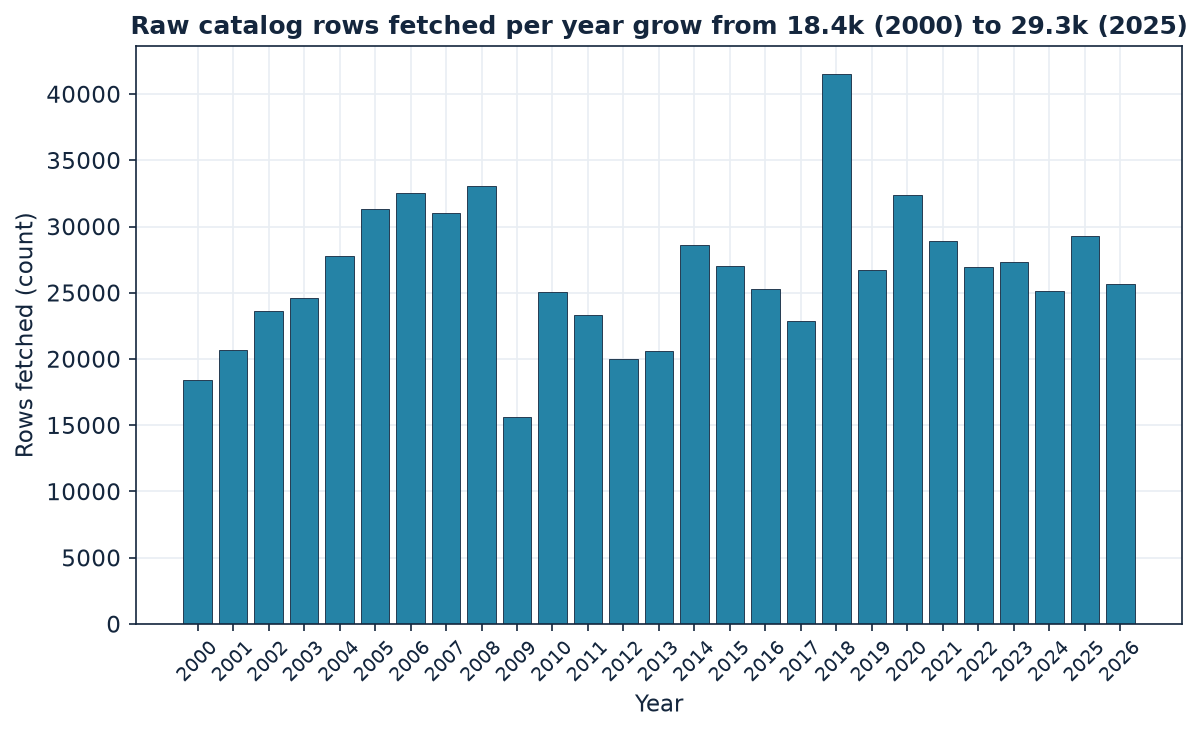

,raw_rows
year,
2000,18381
2001,20644
2002,23656
2003,24586
2004,27773
2005,31340
2006,32503
2007,31017
2008,33065


In [4]:
yearly = months.groupby("year")["rows"].sum()

fig, ax = plt.subplots(figsize=(9, 5))
ax.bar(yearly.index.astype(str), yearly.values, color=ACCENT, edgecolor=NAVY, linewidth=0.4)
ax.set_title("Raw catalog rows fetched per year grow from 18.4k (2000) to 29.3k (2025)")
ax.set_xlabel("Year")
ax.set_ylabel("Rows fetched (count)")
ax.tick_params(axis="x", rotation=45, labelsize=9)
save(fig, "eda_event_counts_by_year.png")

yearly.to_frame("raw_rows")

## 3. Idempotency: why a re-run does not rewrite history

The manifest stores a **sha256 per month** of the payload that was written to disk.
Two consequences:

1. **Audit** — any month can be re-hashed later and compared with the recorded value;
   a mismatch means the file on disk is not what the run reported.
2. **Idempotency** — a resumed run compares the recorded hash (and row count) before
   re-downloading, so completed months are skipped and the raw store converges to the
   same bytes regardless of how many times the collector is interrupted and restarted.

The audit below re-hashes a sample of files and checks row counts for **all 323**
files against the manifest (row counts come from Parquet metadata, so it is fast).

In [5]:
sample_months = ["2000-01", "2011-03", "2018-07", "2026-11"]
for m in sample_months:
    digest = hashlib.sha256(Path(f"data/raw/{m}.parquet").read_bytes()).hexdigest()
    recorded = manifest["months"][m]["sha256"]
    print(f"{m}: sha256 match = {digest == recorded}")

mismatches = 0
file_rows = 0
for m, rec in manifest["months"].items():
    n_rows = pq.ParquetFile(Path("data/raw") / f"{m}.parquet").metadata.num_rows
    file_rows += n_rows
    if n_rows != rec["rows"]:
        mismatches += 1
        print(f"  row-count mismatch: {m} file={n_rows} manifest={rec['rows']}")

print(f"\nfiles audited        : {len(months)}")
print(f"rows read from files : {file_rows:,} (manifest: {months['rows'].sum():,})")
print(f"row-count mismatches : {mismatches}")
print(f"max rows in one chunk: {months['rows'].max():,} (API cap = 20,000)")

2000-01: sha256 match = True
2011-03: sha256 match = True
2018-07: sha256 match = True
2026-11: sha256 match = True

files audited        : 323
rows read from files : 715,183 (manifest: 715,183)
row-count mismatches : 0
max rows in one chunk: 7,678 (API cap = 20,000)


## 4. Raw → processed reduction

The cleaning stage (notebook 02) filters out non-earthquake event types and
de-duplicates on the event `id`. The quality report
`reports/data_quality/data_quality.json` records the outcome of that stage:

In [6]:
quality = json.loads(Path("reports/data_quality/data_quality.json").read_text())

reduction = pd.DataFrame(
    [
        ("raw rows fetched (323 monthly files)", quality["total_raw_rows"]),
        ("removed: non-earthquake event types", -quality["non_earthquake_removed"]),
        ("removed: duplicate ids", -quality["duplicates_removed"]),
        ("processed rows (data/processed/earthquakes.parquet)", quality["processed_rows"]),
    ],
    columns=["step", "rows"],
).set_index("step")
reduction["rows"] = reduction["rows"].map("{:,}".format)

pct_removed = 100 * quality["non_earthquake_removed"] / quality["total_raw_rows"]
print(reduction.to_string())
print(f"\nnon-earthquake share removed: {pct_removed:.2f}%")
print(f"date range: {quality['date_range']['start']} → {quality['date_range']['end']}")
print(f"magnitude range: {quality['magnitude_range']['min']} → {quality['magnitude_range']['max']}")

                                                        rows
step                                                        
raw rows fetched (323 monthly files)                 715,183
removed: non-earthquake event types                   -7,745
removed: duplicate ids                                     0
processed rows (data/processed/earthquakes.parquet)  707,438

non-earthquake share removed: 1.08%
date range: 2000-01-01T01:19:26.990000+00:00 → 2026-11-15T23:04:21.749000+00:00
magnitude range: 0.7 → 9.1


### Reproducing this notebook

```bash
tools/build_notebooks.py 01     # convert notebooks/01_data_collection.py → .ipynb and execute
```

The `.py` source is the source of truth; the executed `.ipynb` is generated. Because
the notebook only reads `data/raw/manifest.json`, the monthly Parquet files, and the
quality report, its outputs are reproducible offline and byte-for-byte stable as long
as the raw store is unchanged.